TESTING SAVED MODELS AGAINST DIFFERENT STANDARD TQ VALUES

📂 Loading from: model_evaluation_20260306_112617
📁 Saving to: model_evaluation_20260306_112617/tq_comparison

🤖 Loading trained models...
  ✅ Loaded: AdaBoost
  ✅ Loaded: Bagging
  ✅ Loaded: Bayesian Ridge
  ✅ Loaded: Decision Tree
  ✅ Loaded: Elastic Net
  ✅ Loaded: Extra Trees
  ✅ Loaded: Gradient Boosting
  ✅ Loaded: Hist Gradient Boosting
  ✅ Loaded: Huber Regressor
  ✅ Loaded: Kernel Ridge
  ✅ Loaded: KNN
  ✅ Loaded: Lasso
  ✅ Loaded: Linear Regression
  ✅ Loaded: MLP
  ✅ Loaded: Passive Aggressive
  ✅ Loaded: PLS Regression
  ✅ Loaded: Polynomial deg 2
  ✅ Loaded: Polynomial deg 3
  ✅ Loaded: Random Forest
  ✅ Loaded: Ridge
  ✅ Loaded: SGD Regressor
  ✅ Loaded: SVR Linear
  ✅ Loaded: SVR RBF
  ✅ Loaded: Voting Ensemble
  ✅ Loaded: XGBoost

✅ Loaded 25 models

📂 Loading dataset...
✅ Loaded from: Kargahi_Movaghar_Source_Data.csv
✅ Simulation functions loaded

🧪 Testing on 500 windows against 6 TQ values...

📊 Testing agains

TQ=6: 100%|██████████| 500/500 [00:37<00:00, 13.38it/s]



📊 Testing against Standard TQ = 8


TQ=8: 100%|██████████| 500/500 [00:32<00:00, 15.19it/s]



📊 Testing against Standard TQ = 10


...


📊 Testing against Standard TQ = 20


TQ=20: 100%|██████████| 500/500 [00:32<00:00, 15.33it/s]



📊 Testing against Standard TQ = 25


TQ=25: 100%|██████████| 500/500 [00:33<00:00, 15.08it/s]



🎨 Creating visualizations...


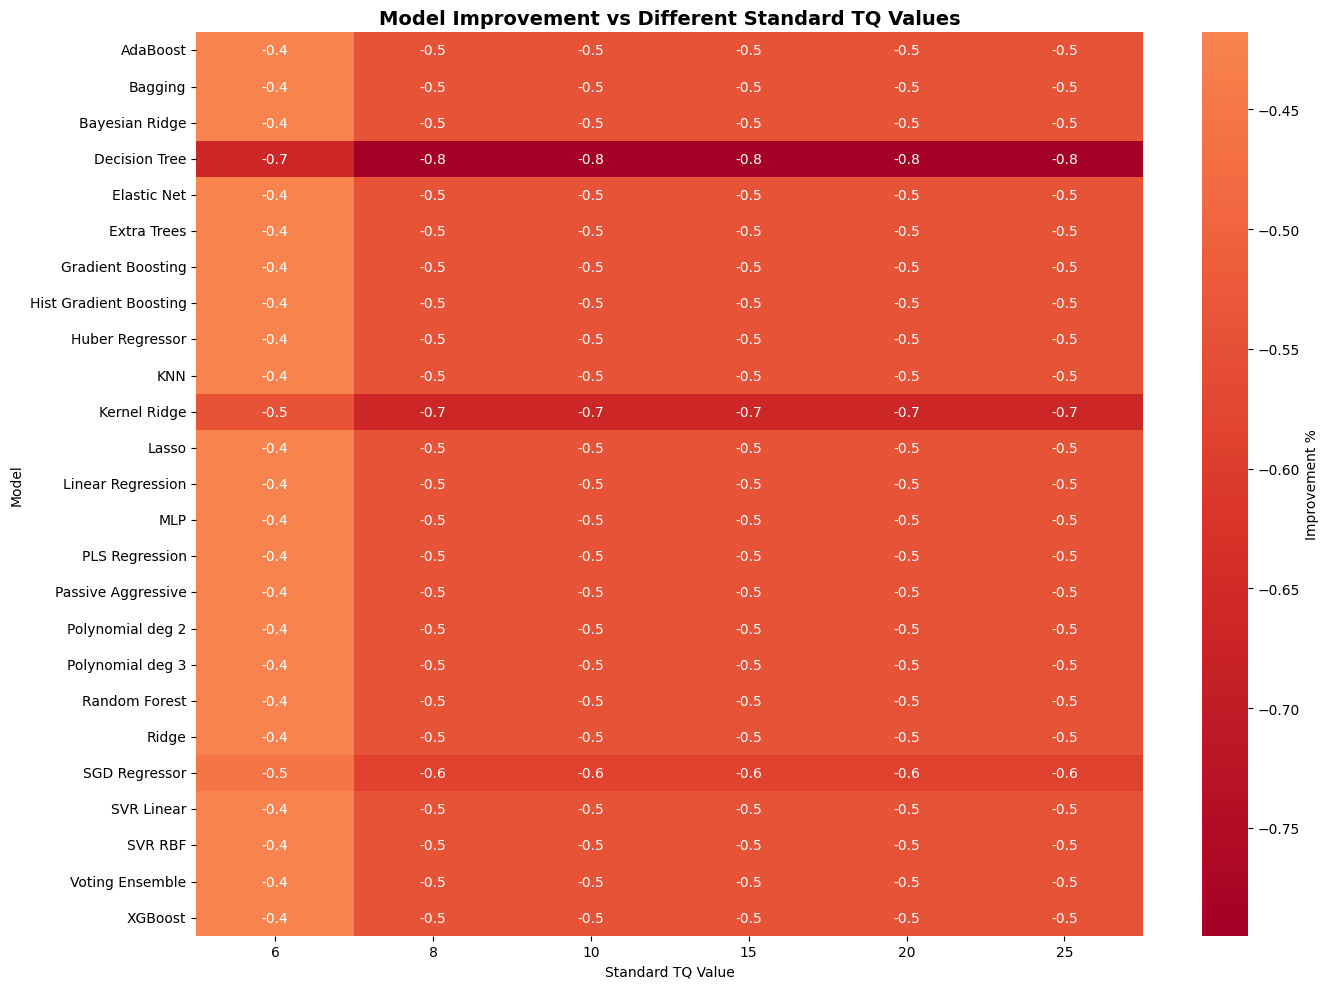

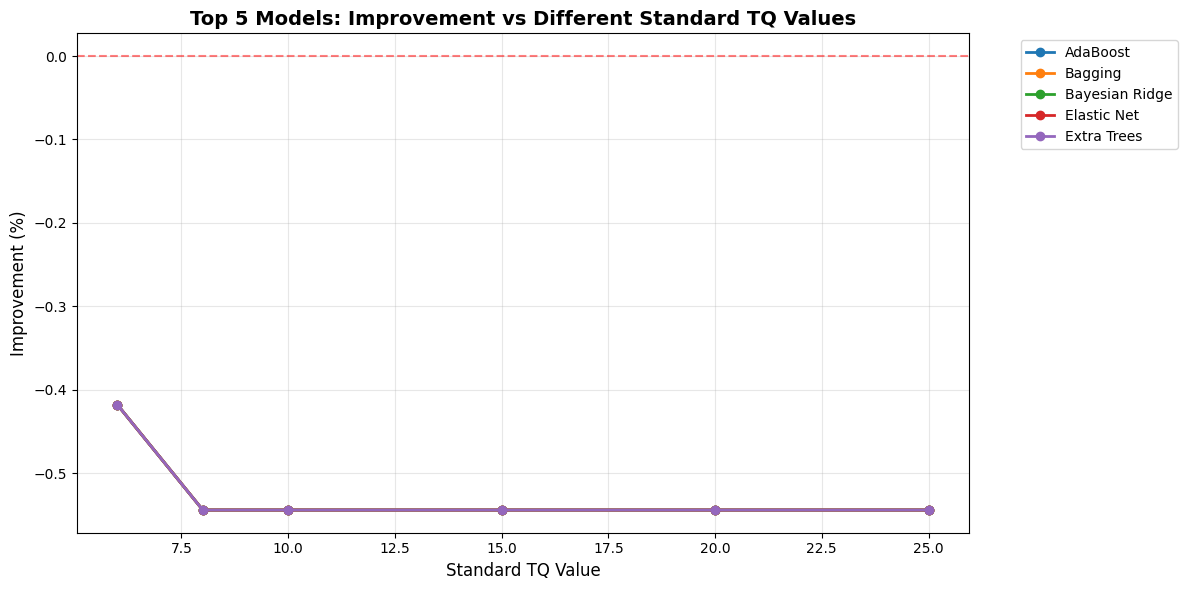

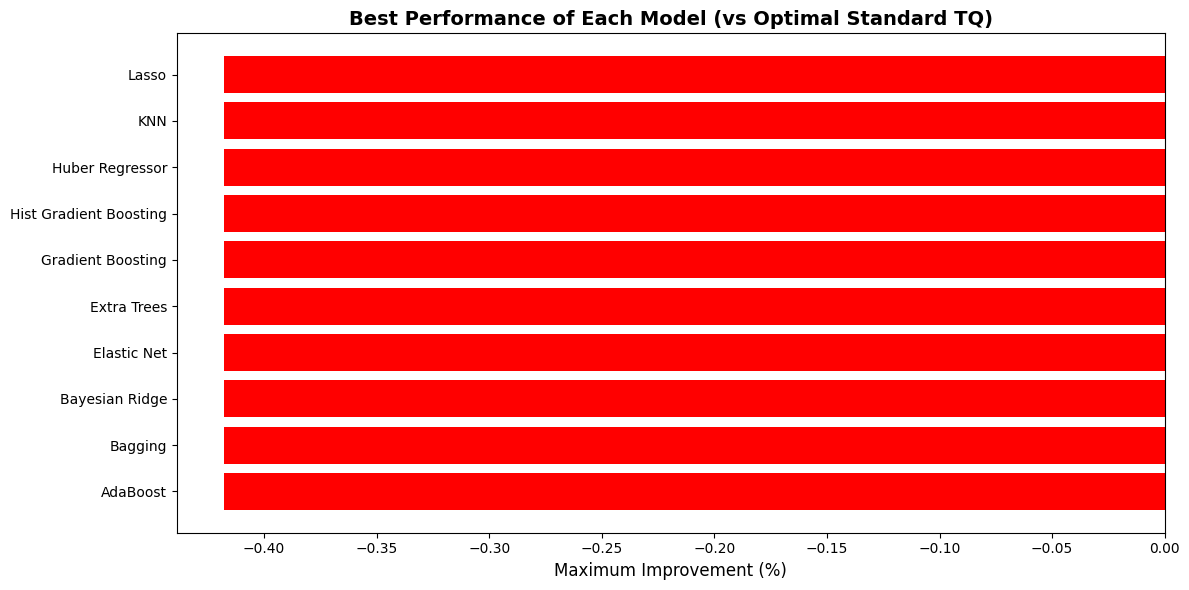

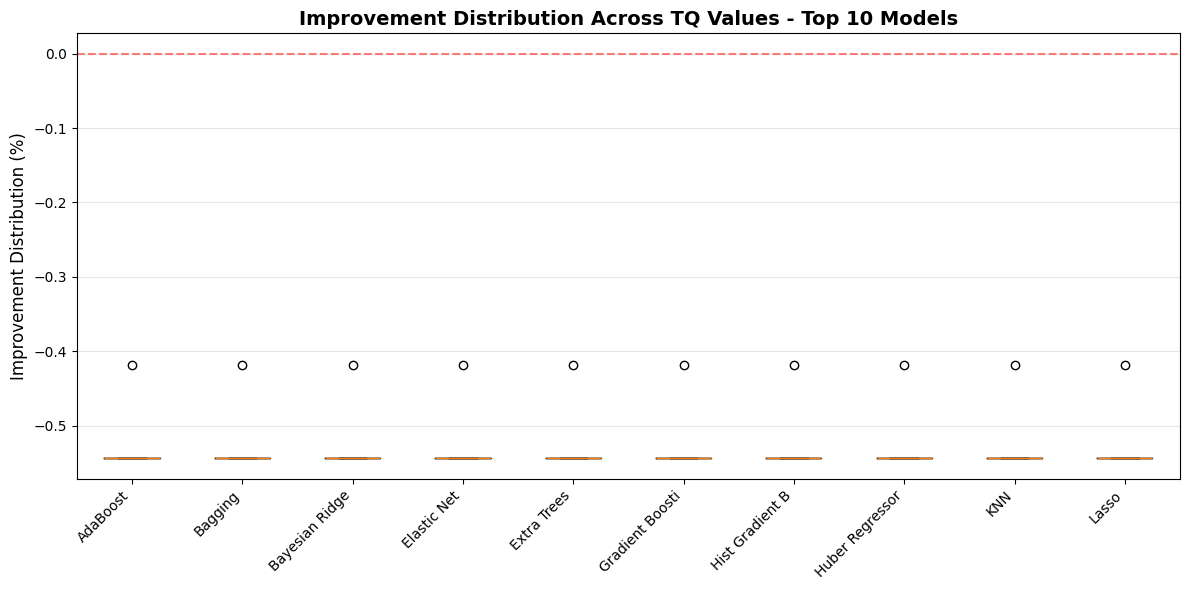

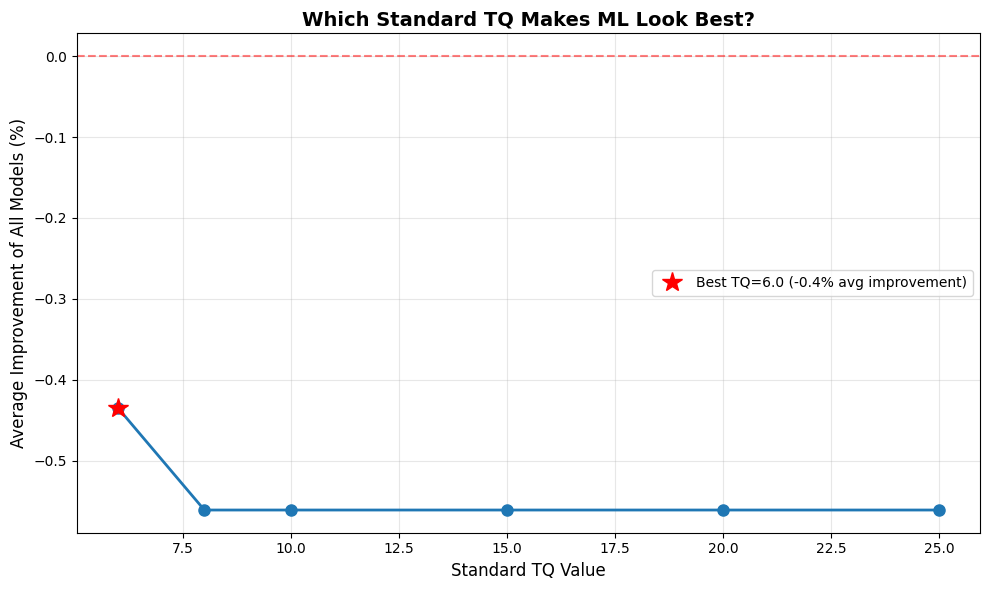

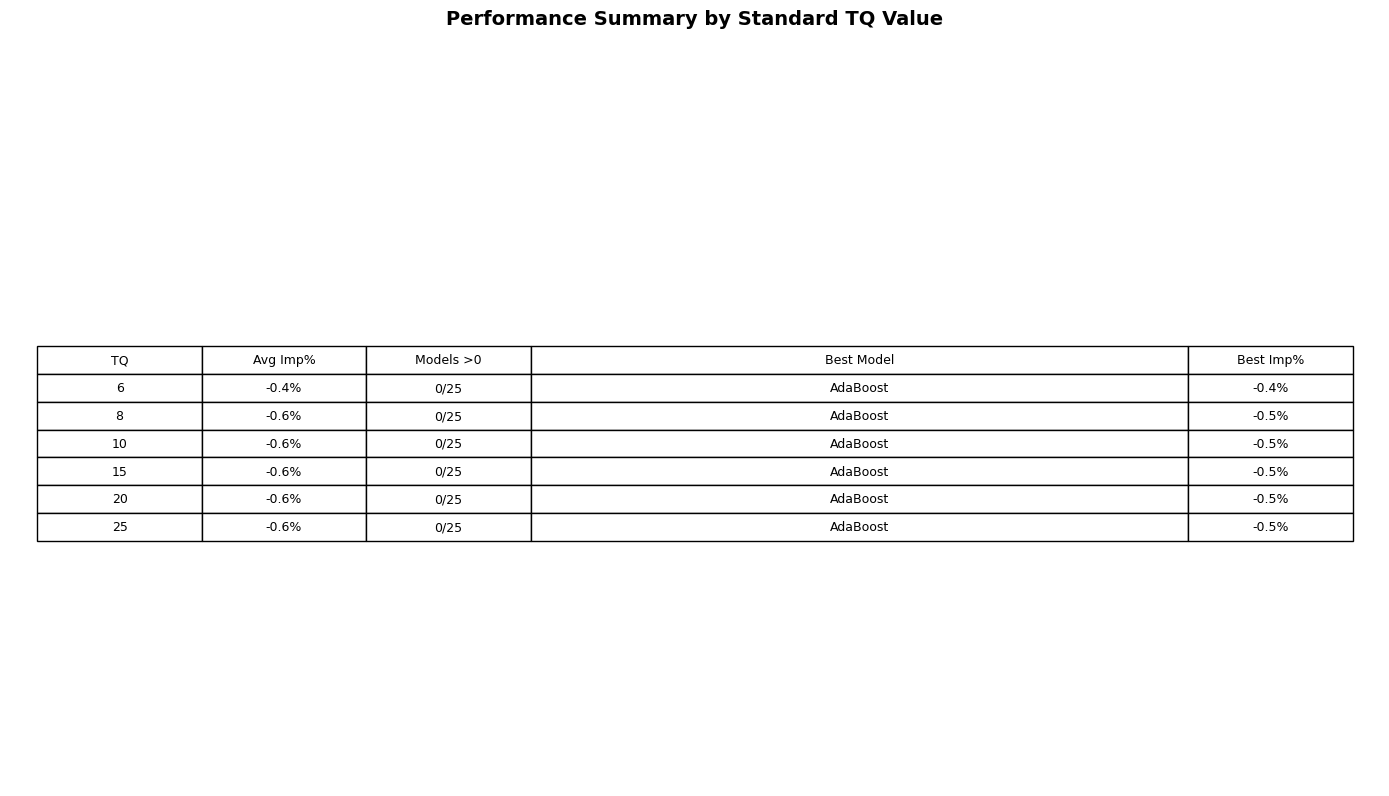


SUMMARY: BEST STANDARD TQ FOR ML COMPARISON

📊 TQ = 6:
  • Average improvement: -0.4%
  • Models with improvement: 0/25
  • Best model: AdaBoost
  • Best improvement: -0.4%

📊 TQ = 8:
  • Average improvement: -0.6%
  • Models with improvement: 0/25
  • Best model: AdaBoost
  • Best improvement: -0.5%

📊 TQ = 10:
  • Average improvement: -0.6%
  • Models with improvement: 0/25
  • Best model: AdaBoost
  • Best improvement: -0.5%

📊 TQ = 15:
  • Average improvement: -0.6%
  • Models with improvement: 0/25
  • Best model: AdaBoost
  • Best improvement: -0.5%

📊 TQ = 20:
  • Average improvement: -0.6%
  • Models with improvement: 0/25
  • Best model: AdaBoost
  • Best improvement: -0.5%

📊 TQ = 25:
  • Average improvement: -0.6%
  • Models with improvement: 0/25
  • Best model: AdaBoost
  • Best improvement: -0.5%

🏆 Best TQ for showcasing ML: 6
   (ML models show highest average improvement when compared to TQ=6)

✅ All results saved to: model_evaluation_20260306_112617/tq_comparison/


In [1]:
# CELL: TEST SAVED MODELS ON DIFFERENT STANDARD TQ VALUES
# =======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import random 
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# ============================================
# CONFIGURATION
# ============================================
EXPERIMENT_DIR = "model_evaluation_20260306_112617"  # CHANGE THIS to your folder
OUTPUT_DIR = f"{EXPERIMENT_DIR}/tq_comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Different TQ values to test as standard
STANDARD_TQ_VALUES = [6, 8, 10, 15, 20, 25]

WINDOW_SIZE = 7
CS_OVERHEAD = 0.05
N_TEST_WINDOWS = 500
RANDOM_SEED = 42
CANDIDATE_SLICES = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 5.0]

np.random.seed(RANDOM_SEED)

print("="*80)
print("TESTING SAVED MODELS AGAINST DIFFERENT STANDARD TQ VALUES")
print("="*80)
print(f"\n📂 Loading from: {EXPERIMENT_DIR}")
print(f"📁 Saving to: {OUTPUT_DIR}")

# ============================================
# LOAD SAVED MODELS
# ============================================
print("\n🤖 Loading trained models...")

models_dir = f"{EXPERIMENT_DIR}/models"
trained_models = {}

for filename in os.listdir(models_dir):
    if filename.endswith('.pkl'):
        model_path = os.path.join(models_dir, filename)
        model_name = filename.replace('.pkl', '').replace('_', ' ')
        try:
            trained_models[model_name] = joblib.load(model_path)
            print(f"  ✅ Loaded: {model_name[:30]}")
        except Exception as e:
            print(f"  ❌ Failed: {filename}")

print(f"\n✅ Loaded {len(trained_models)} models")

# ============================================
# LOAD ORIGINAL DATASET
# ============================================
print("\n📂 Loading dataset...")

df = None
possible_paths = [
    "Kargahi_Movaghar_Source_Data.csv",
    "../Kargahi_Movaghar_Source_Data.csv",
    f"{EXPERIMENT_DIR}/../Kargahi_Movaghar_Source_Data.csv"
]

for path in possible_paths:
    try:
        df = pd.read_csv(path)
        print(f"✅ Loaded from: {path}")
        break
    except:
        continue

if df is None:
    print("⚠️ Creating synthetic dataset...")
    n_jobs = 10000
    df = pd.DataFrame({
        'Job_ID': range(1, n_jobs + 1),
        'Arrival_Time': np.cumsum(np.random.exponential(1.0, n_jobs)),
        'Service_Time': np.random.exponential(2.0, n_jobs),
        'Deadline_Exp': np.random.uniform(5, 20, n_jobs)
    })
    print(f"✅ Created synthetic dataset: {df.shape}")

# ============================================
# SIMULATION FUNCTIONS (copied from original)
# ============================================
class SimulationCache:
    def __init__(self):
        self.cache = {}
        self.hits = 0
        self.misses = 0
    
    def get_key(self, batch_df, tq):
        return (batch_df['Job_ID'].iloc[0], batch_df['Arrival_Time'].iloc[0], tq)
    
    def get(self, batch_df, tq):
        key = self.get_key(batch_df, tq)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        return None
    
    def put(self, batch_df, tq, result):
        self.cache[self.get_key(batch_df, tq)] = result

sim_cache = SimulationCache()

def run_detailed_simulation(df_batch, tq, use_cache=True):
    if use_cache:
        cached = sim_cache.get(df_batch, tq)
        if cached: return cached
    
    time_val = df_batch['Arrival_Time'].min()
    jobs = df_batch.copy().rename(columns={'Service_Time': 'bt', 'Deadline_Exp': 'deadline'})
    jobs = jobs.sort_values('Arrival_Time').reset_index(drop=True)
    
    jobs['completion_time'] = np.nan
    jobs['first_start_time'] = np.nan
    jobs['waiting_time'] = 0
    jobs['turnaround_time'] = 0
    jobs['response_time'] = 0
    jobs['times_preempted'] = 0
    
    jobs_list = jobs.to_dict('records')
    ready_queue = []
    completed = 0
    misses = 0
    last_pid = None
    context_switches = 0
    turnaround_times = []
    waiting_times = []
    response_times = []
    preemptions = []
    
    while completed < len(jobs_list) or ready_queue:
        while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
            ready_queue.append(jobs_list.pop(0))
        
        if not ready_queue:
            if jobs_list:
                time_val = jobs_list[0]['Arrival_Time']
                continue
            break

        ready_queue.sort(key=lambda x: x['deadline'])
        p = ready_queue.pop(0)

        if pd.isna(p['first_start_time']):
            p['first_start_time'] = time_val
            p['waiting_time'] = time_val - p['Arrival_Time']
            p['response_time'] = time_val - p['Arrival_Time']
            waiting_times.append(p['waiting_time'])
            response_times.append(p['response_time'])

        if last_pid is not None and last_pid != p['Job_ID']:
            time_val += CS_OVERHEAD
            context_switches += 1
        
        exec_time = min(p['bt'], tq)
        if p['bt'] < tq * 1.1: 
            exec_time = p['bt']
            
        p['bt'] -= exec_time
        time_val += exec_time
        last_pid = p['Job_ID']

        if p['bt'] <= 0:
            p['completion_time'] = time_val
            if time_val > p['deadline']:
                misses += 1
            turnaround_times.append(time_val - p['Arrival_Time'])
            completed += 1
            preemptions.append(p['times_preempted'])
        else:
            p['times_preempted'] += 1
            while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
                ready_queue.append(jobs_list.pop(0))
            ready_queue.append(p)
    
    result = {
        'misses': misses,
        'miss_rate': misses / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        'avg_waiting_time': np.mean(waiting_times) if waiting_times else 0,
        'max_waiting_time': np.max(waiting_times) if waiting_times else 0,
        'std_waiting_time': np.std(waiting_times) if waiting_times else 0,
        'avg_turnaround_time': np.mean(turnaround_times) if turnaround_times else 0,
        'max_turnaround_time': np.max(turnaround_times) if turnaround_times else 0,
        'std_turnaround_time': np.std(turnaround_times) if turnaround_times else 0,
        'avg_response_time': np.mean(response_times) if response_times else 0,
        'max_response_time': np.max(response_times) if response_times else 0,
        'context_switches': context_switches,
        'avg_preemptions': np.mean(preemptions) if preemptions else 0,
        'total_preemptions': sum(preemptions),
        'throughput': completed / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0
    }
    
    if use_cache:
        sim_cache.put(df_batch, tq, result)
    return result

def get_real_features(df_batch):
    return {
        'avg_service': df_batch['Service_Time'].mean(),
        'arrival_rate': len(df_batch) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'min_deadline': df_batch['Deadline_Exp'].min(),
        'max_deadline': df_batch['Deadline_Exp'].max(),
        'service_std': df_batch['Service_Time'].std(),
        'service_skew': df_batch['Service_Time'].skew(),
        'deadline_range': df_batch['Deadline_Exp'].max() - df_batch['Deadline_Exp'].min(),
        'job_count': len(df_batch),
        'utilization': (df_batch['Service_Time'].sum()) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'deadline_variance': df_batch['Deadline_Exp'].var(),
        'service_quantile_25': df_batch['Service_Time'].quantile(0.25),
        'service_quantile_75': df_batch['Service_Time'].quantile(0.75)
    }

print("✅ Simulation functions loaded")

# ============================================
# TEST WINDOWS
# ============================================
print(f"\n🧪 Testing on {N_TEST_WINDOWS} windows against {len(STANDARD_TQ_VALUES)} TQ values...")

total_possible = list(range(0, len(df) - WINDOW_SIZE, 1))
test_indices = random.sample(total_possible, min(N_TEST_WINDOWS, len(total_possible)))

# Store results for each TQ value
all_results = []

for std_tq in STANDARD_TQ_VALUES:
    print(f"\n📊 Testing against Standard TQ = {std_tq}")
    
    # Initialize metrics for this TQ
    standard_misses_total = 0
    model_results = {name: {'misses_total': 0, 'improvements': []} for name in trained_models}
    
    for idx in tqdm(test_indices, desc=f"TQ={std_tq}"):
        batch = df.iloc[idx:idx+WINDOW_SIZE]
        features = pd.DataFrame([get_real_features(batch)])
        
        # Standard with current TQ
        std_result = run_detailed_simulation(batch, tq=std_tq)
        standard_misses_total += std_result['misses']
        
        # Test each model
        for model_name, model in trained_models.items():
            try:
                pred_tq = float(model.predict(features)[0])
                closest_tq = min(CANDIDATE_SLICES, key=lambda x: abs(x - pred_tq))
                ml_result = run_detailed_simulation(batch, tq=closest_tq)
                
                model_results[model_name]['misses_total'] += ml_result['misses']
                
            except:
                pass
    
    # Calculate improvements
    for model_name in trained_models:
        if standard_misses_total > 0:
            improvement = ((standard_misses_total - model_results[model_name]['misses_total']) / 
                          standard_misses_total * 100)
        else:
            improvement = 0
            
        all_results.append({
            'Standard_TQ': std_tq,
            'Model': model_name,
            'Standard_Misses': standard_misses_total,
            'Model_Misses': model_results[model_name]['misses_total'],
            'Improvement': improvement
        })

# Convert to DataFrame
results_df = pd.DataFrame(all_results)

# ============================================
# VISUALIZATIONS
# ============================================
print("\n🎨 Creating visualizations...")

# 1. Heatmap: Model Performance Across TQ Values
plt.figure(figsize=(14, 10))
pivot_data = results_df.pivot(index='Model', columns='Standard_TQ', values='Improvement')
sns.heatmap(pivot_data, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Improvement %'})
plt.title('Model Improvement vs Different Standard TQ Values', fontsize=14, fontweight='bold')
plt.xlabel('Standard TQ Value')
plt.ylabel('Model')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/1_improvement_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

# 2. Line plot: Best models across TQ values
plt.figure(figsize=(12, 6))
top_models = results_df.groupby('Model')['Improvement'].mean().nlargest(5).index
for model in top_models:
    model_data = results_df[results_df['Model'] == model]
    plt.plot(model_data['Standard_TQ'], model_data['Improvement'], 'o-', linewidth=2, label=model[:20])

plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Standard TQ Value', fontsize=12)
plt.ylabel('Improvement (%)', fontsize=12)
plt.title('Top 5 Models: Improvement vs Different Standard TQ Values', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/2_top_models_line.png", dpi=150, bbox_inches='tight')
plt.show()

# 3. Bar plot: Best TQ for each model
plt.figure(figsize=(12, 6))
best_tq_per_model = results_df.loc[results_df.groupby('Model')['Improvement'].idxmax()]
best_tq_per_model = best_tq_per_model.nlargest(10, 'Improvement')
colors = ['green' if x > 0 else 'red' for x in best_tq_per_model['Improvement']]
plt.barh(range(len(best_tq_per_model)), best_tq_per_model['Improvement'], color=colors)
plt.yticks(range(len(best_tq_per_model)), [m[:25] for m in best_tq_per_model['Model']])
plt.xlabel('Maximum Improvement (%)', fontsize=12)
plt.title('Best Performance of Each Model (vs Optimal Standard TQ)', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/3_best_per_model.png", dpi=150, bbox_inches='tight')
plt.show()

# 4. Box plot: Improvement distribution for top models
plt.figure(figsize=(12, 6))
top10_models = results_df.groupby('Model')['Improvement'].mean().nlargest(10).index
plot_data = [results_df[results_df['Model'] == m]['Improvement'].values for m in top10_models]
plt.boxplot(plot_data, labels=[m[:15] for m in top10_models])
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.ylabel('Improvement Distribution (%)', fontsize=12)
plt.title('Improvement Distribution Across TQ Values - Top 10 Models', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/4_improvement_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

# 5. Which TQ is best for ML?
plt.figure(figsize=(10, 6))
tq_performance = results_df.groupby('Standard_TQ')['Improvement'].mean().reset_index()
plt.plot(tq_performance['Standard_TQ'], tq_performance['Improvement'], 'o-', linewidth=2, markersize=8)
best_tq = tq_performance.loc[tq_performance['Improvement'].idxmax()]
plt.plot(best_tq['Standard_TQ'], best_tq['Improvement'], 'r*', markersize=15, 
         label=f"Best TQ={best_tq['Standard_TQ']} ({best_tq['Improvement']:.1f}% avg improvement)")
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Standard TQ Value', fontsize=12)
plt.ylabel('Average Improvement of All Models (%)', fontsize=12)
plt.title('Which Standard TQ Makes ML Look Best?', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/5_best_tq_for_ml.png", dpi=150, bbox_inches='tight')
plt.show()

# 6. Summary table
fig, ax = plt.subplots(figsize=(14, 8))
ax.axis('off')

summary_data = []
for tq in STANDARD_TQ_VALUES:
    tq_data = results_df[results_df['Standard_TQ'] == tq]
    best_model = tq_data.loc[tq_data['Improvement'].idxmax()]
    avg_improvement = tq_data['Improvement'].mean()
    models_positive = (tq_data['Improvement'] > 0).sum()
    models_negative = (tq_data['Improvement'] < 0).sum()
    
    summary_data.append([
        tq,
        f"{avg_improvement:.1f}%",
        f"{models_positive}/{models_positive+models_negative}",
        best_model['Model'][:25],
        f"{best_model['Improvement']:.1f}%"
    ])

table = ax.table(cellText=summary_data,
                 colLabels=['TQ', 'Avg Imp%', 'Models >0', 'Best Model', 'Best Imp%'],
                 cellLoc='center', loc='center',
                 colWidths=[0.1, 0.1, 0.1, 0.4, 0.1])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)
ax.set_title('Performance Summary by Standard TQ Value', fontsize=14, fontweight='bold', y=1.1)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/6_summary_table.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# SAVE RESULTS
# ============================================
results_df.to_csv(f"{OUTPUT_DIR}/tq_comparison_results.csv", index=False)

print("\n" + "="*80)
print("SUMMARY: BEST STANDARD TQ FOR ML COMPARISON")
print("="*80)

for tq in STANDARD_TQ_VALUES:
    tq_data = results_df[results_df['Standard_TQ'] == tq]
    avg_imp = tq_data['Improvement'].mean()
    best_imp = tq_data['Improvement'].max()
    best_model = tq_data.loc[tq_data['Improvement'].idxmax(), 'Model']
    print(f"\n📊 TQ = {tq}:")
    print(f"  • Average improvement: {avg_imp:.1f}%")
    print(f"  • Models with improvement: {(tq_data['Improvement'] > 0).sum()}/{len(tq_data)}")
    print(f"  • Best model: {best_model[:40]}")
    print(f"  • Best improvement: {best_imp:.1f}%")

best_overall_tq = results_df.groupby('Standard_TQ')['Improvement'].mean().idxmax()
print(f"\n🏆 Best TQ for showcasing ML: {best_overall_tq}")
print(f"   (ML models show highest average improvement when compared to TQ={best_overall_tq})")

print(f"\n✅ All results saved to: {OUTPUT_DIR}/")
print("="*80)

TESTING SAVED MODELS AGAINST DIFFERENT STANDARD TQ VALUES

📂 Loading from: model_evaluation_20260306_112617
📁 Saving to: model_evaluation_20260306_112617/tq_comparison

🤖 Loading trained models...
  ✅ Loaded: AdaBoost
  ✅ Loaded: Bagging
  ✅ Loaded: Bayesian Ridge
  ✅ Loaded: Decision Tree
  ✅ Loaded: Elastic Net
  ✅ Loaded: Extra Trees
  ✅ Loaded: Gradient Boosting
  ✅ Loaded: Hist Gradient Boosting
  ✅ Loaded: Huber Regressor
  ✅ Loaded: Kernel Ridge
  ✅ Loaded: KNN
  ✅ Loaded: Lasso
  ✅ Loaded: Linear Regression
  ✅ Loaded: MLP
  ✅ Loaded: Passive Aggressive
  ✅ Loaded: PLS Regression
  ✅ Loaded: Polynomial deg 2
  ✅ Loaded: Polynomial deg 3
  ✅ Loaded: Random Forest
  ✅ Loaded: Ridge
  ✅ Loaded: SGD Regressor
  ✅ Loaded: SVR Linear
  ✅ Loaded: SVR RBF
  ✅ Loaded: Voting Ensemble
  ✅ Loaded: XGBoost

✅ Loaded 25 models

📂 Loading dataset...
✅ Loaded from: Kargahi_Movaghar_Source_Data.csv
✅ Simulation functions loaded

🧪 Testing on 500 windows against 7 TQ values...

📊 Testing agains

TQ=0.1: 100%|██████████| 500/500 [00:34<00:00, 14.45it/s]



📊 Testing against Standard TQ = 0.2


TQ=0.2: 100%|██████████| 500/500 [00:32<00:00, 15.62it/s]



📊 Testing against Standard TQ = 0.5


...


📊 Testing against Standard TQ = 2.0


TQ=2.0: 100%|██████████| 500/500 [01:36<00:00,  5.21it/s]



📊 Testing against Standard TQ = 5.0


TQ=5.0: 100%|██████████| 500/500 [01:32<00:00,  5.39it/s]



🎨 Creating visualizations...


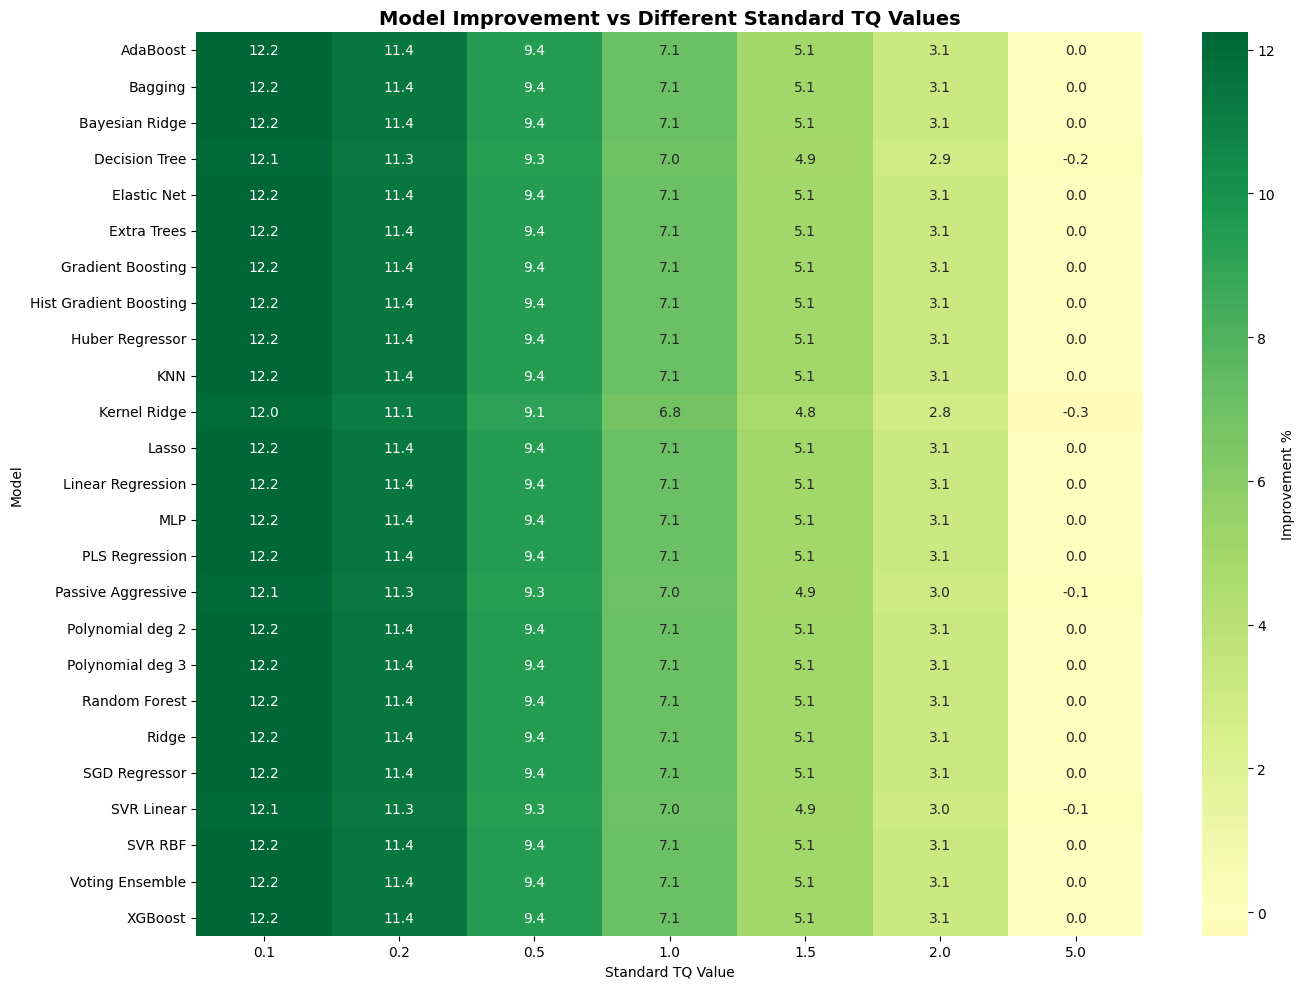

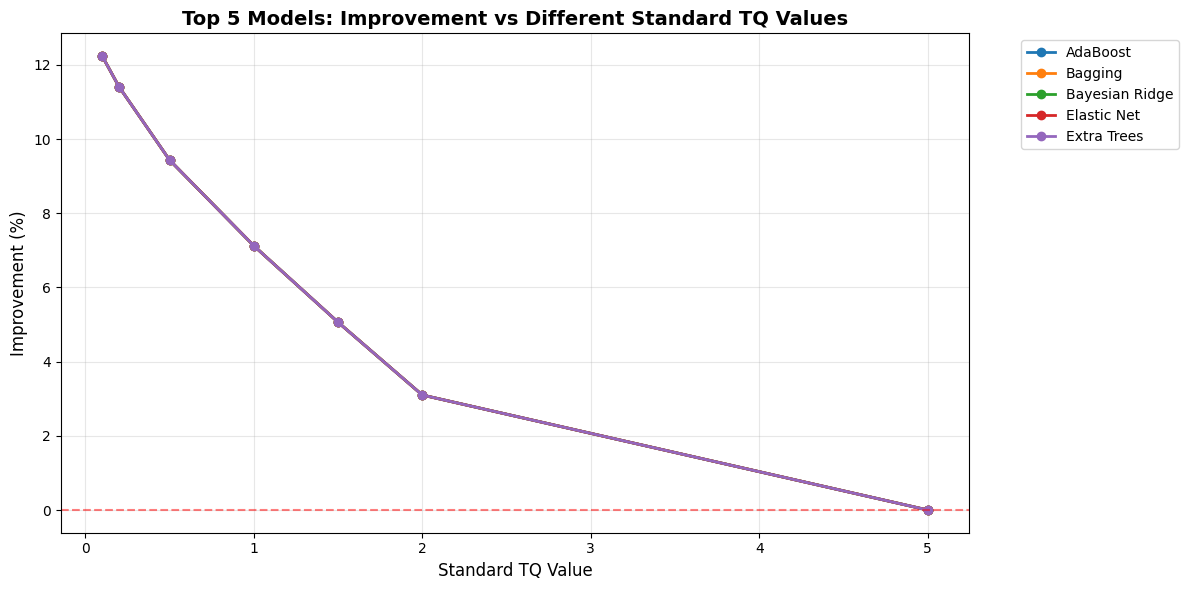

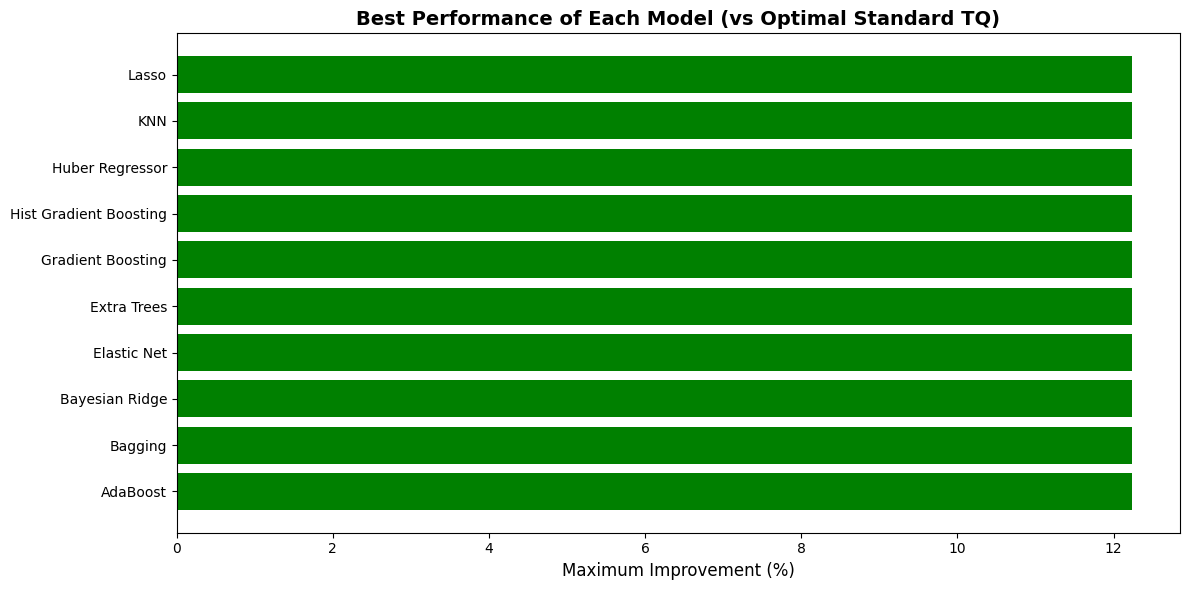

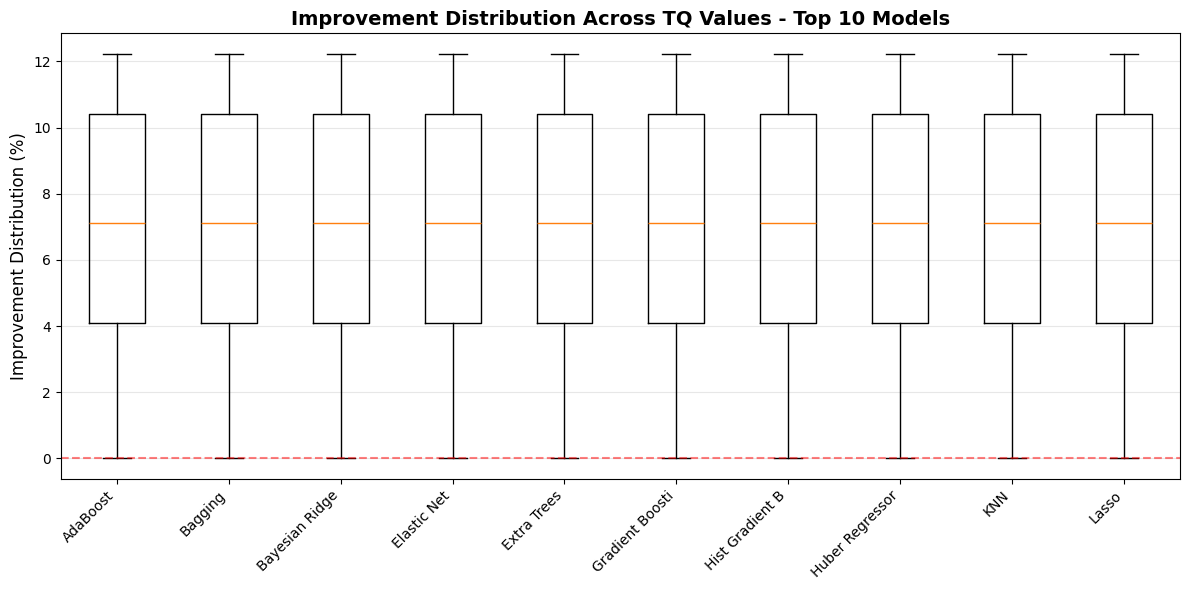

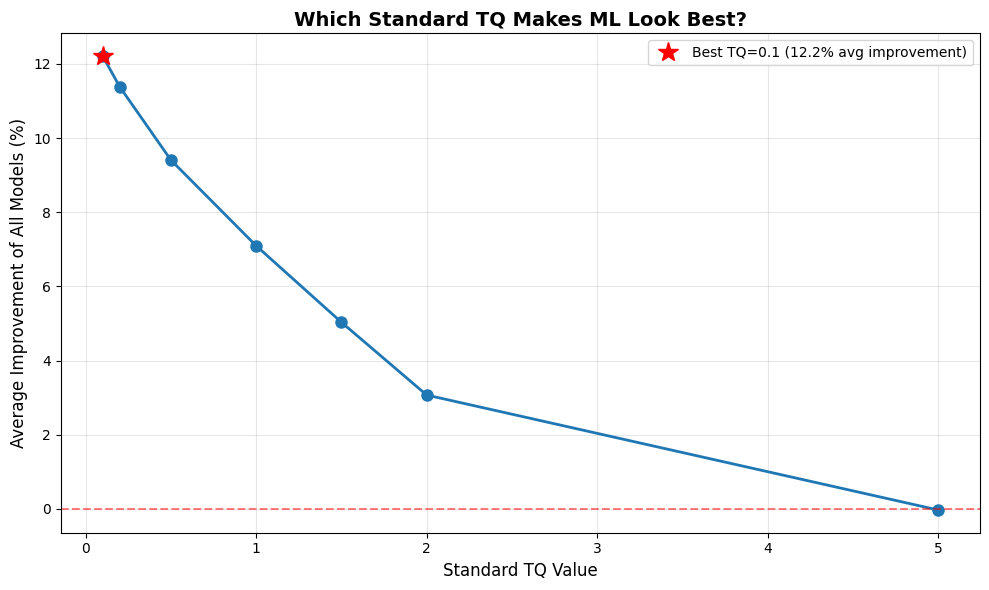

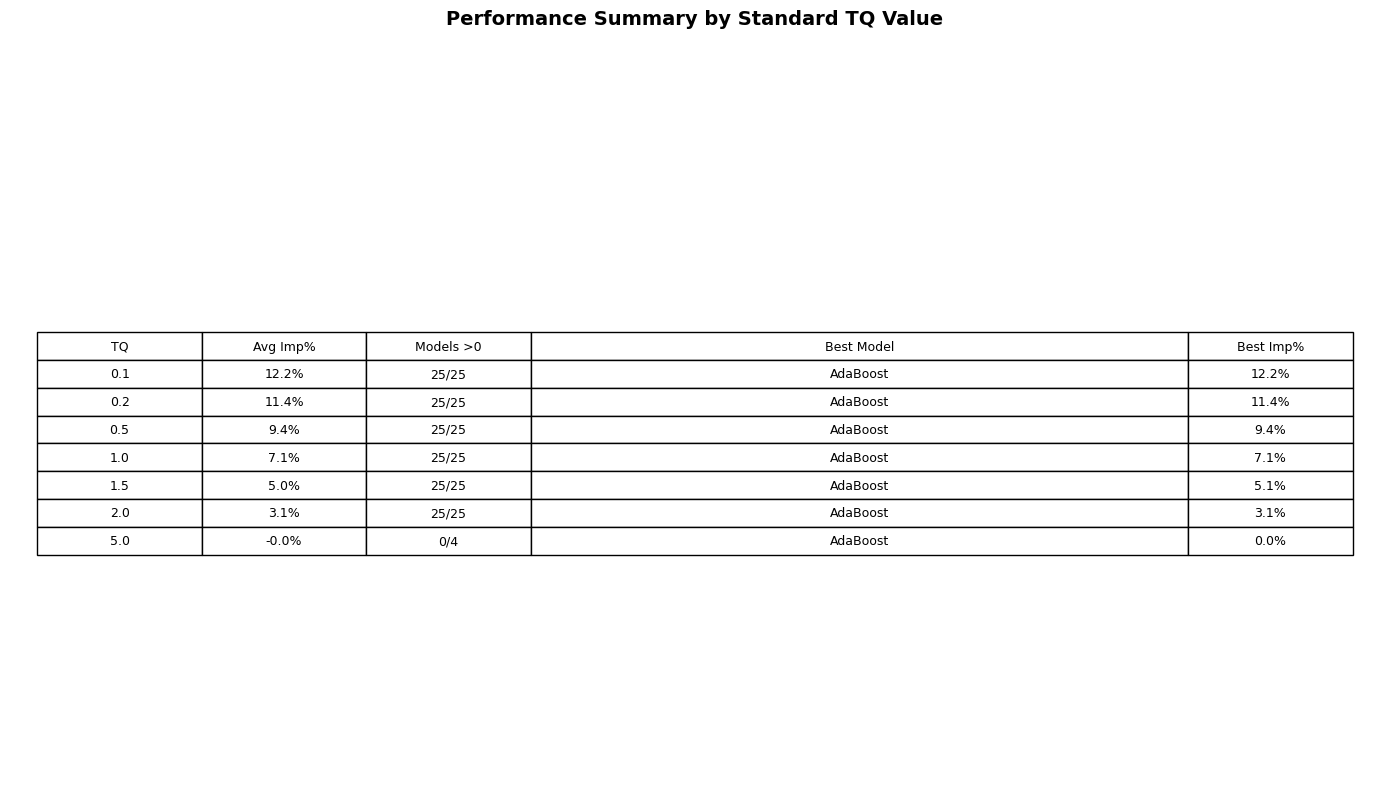


SUMMARY: BEST STANDARD TQ FOR ML COMPARISON

📊 TQ = 0.1:
  • Average improvement: 12.2%
  • Models with improvement: 25/25
  • Best model: AdaBoost
  • Best improvement: 12.2%

📊 TQ = 0.2:
  • Average improvement: 11.4%
  • Models with improvement: 25/25
  • Best model: AdaBoost
  • Best improvement: 11.4%

📊 TQ = 0.5:
  • Average improvement: 9.4%
  • Models with improvement: 25/25
  • Best model: AdaBoost
  • Best improvement: 9.4%

📊 TQ = 1.0:
  • Average improvement: 7.1%
  • Models with improvement: 25/25
  • Best model: AdaBoost
  • Best improvement: 7.1%

📊 TQ = 1.5:
  • Average improvement: 5.0%
  • Models with improvement: 25/25
  • Best model: AdaBoost
  • Best improvement: 5.1%

📊 TQ = 2.0:
  • Average improvement: 3.1%
  • Models with improvement: 25/25
  • Best model: AdaBoost
  • Best improvement: 3.1%

📊 TQ = 5.0:
  • Average improvement: -0.0%
  • Models with improvement: 0/25
  • Best model: AdaBoost
  • Best improvement: 0.0%

🏆 Best TQ for showcasing ML: 0.1
   (ML 

In [2]:
# CELL: TEST SAVED MODELS ON DIFFERENT STANDARD TQ VALUES
# =======================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import random 
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# ============================================
# CONFIGURATION
# ============================================
EXPERIMENT_DIR = "model_evaluation_20260306_112617"  # CHANGE THIS to your folder
OUTPUT_DIR = f"{EXPERIMENT_DIR}/tq_comparison"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Different TQ values to test as standard
STANDARD_TQ_VALUES = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 5.0]

WINDOW_SIZE = 7
CS_OVERHEAD = 0.05
N_TEST_WINDOWS = 500
RANDOM_SEED = 42
CANDIDATE_SLICES = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0, 5.0]

np.random.seed(RANDOM_SEED)

print("="*80)
print("TESTING SAVED MODELS AGAINST DIFFERENT STANDARD TQ VALUES")
print("="*80)
print(f"\n📂 Loading from: {EXPERIMENT_DIR}")
print(f"📁 Saving to: {OUTPUT_DIR}")

# ============================================
# LOAD SAVED MODELS
# ============================================
print("\n🤖 Loading trained models...")

models_dir = f"{EXPERIMENT_DIR}/models"
trained_models = {}

for filename in os.listdir(models_dir):
    if filename.endswith('.pkl'):
        model_path = os.path.join(models_dir, filename)
        model_name = filename.replace('.pkl', '').replace('_', ' ')
        try:
            trained_models[model_name] = joblib.load(model_path)
            print(f"  ✅ Loaded: {model_name[:30]}")
        except Exception as e:
            print(f"  ❌ Failed: {filename}")

print(f"\n✅ Loaded {len(trained_models)} models")

# ============================================
# LOAD ORIGINAL DATASET
# ============================================
print("\n📂 Loading dataset...")

df = None
possible_paths = [
    "Kargahi_Movaghar_Source_Data.csv",
    "../Kargahi_Movaghar_Source_Data.csv",
    f"{EXPERIMENT_DIR}/../Kargahi_Movaghar_Source_Data.csv"
]

for path in possible_paths:
    try:
        df = pd.read_csv(path)
        print(f"✅ Loaded from: {path}")
        break
    except:
        continue

if df is None:
    print("⚠️ Creating synthetic dataset...")
    n_jobs = 10000
    df = pd.DataFrame({
        'Job_ID': range(1, n_jobs + 1),
        'Arrival_Time': np.cumsum(np.random.exponential(1.0, n_jobs)),
        'Service_Time': np.random.exponential(2.0, n_jobs),
        'Deadline_Exp': np.random.uniform(5, 20, n_jobs)
    })
    print(f"✅ Created synthetic dataset: {df.shape}")

# ============================================
# SIMULATION FUNCTIONS (copied from original)
# ============================================
class SimulationCache:
    def __init__(self):
        self.cache = {}
        self.hits = 0
        self.misses = 0
    
    def get_key(self, batch_df, tq):
        return (batch_df['Job_ID'].iloc[0], batch_df['Arrival_Time'].iloc[0], tq)
    
    def get(self, batch_df, tq):
        key = self.get_key(batch_df, tq)
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        self.misses += 1
        return None
    
    def put(self, batch_df, tq, result):
        self.cache[self.get_key(batch_df, tq)] = result

sim_cache = SimulationCache()

def run_detailed_simulation(df_batch, tq, use_cache=True):
    if use_cache:
        cached = sim_cache.get(df_batch, tq)
        if cached: return cached
    
    time_val = df_batch['Arrival_Time'].min()
    jobs = df_batch.copy().rename(columns={'Service_Time': 'bt', 'Deadline_Exp': 'deadline'})
    jobs = jobs.sort_values('Arrival_Time').reset_index(drop=True)
    
    jobs['completion_time'] = np.nan
    jobs['first_start_time'] = np.nan
    jobs['waiting_time'] = 0
    jobs['turnaround_time'] = 0
    jobs['response_time'] = 0
    jobs['times_preempted'] = 0
    
    jobs_list = jobs.to_dict('records')
    ready_queue = []
    completed = 0
    misses = 0
    last_pid = None
    context_switches = 0
    turnaround_times = []
    waiting_times = []
    response_times = []
    preemptions = []
    
    while completed < len(jobs_list) or ready_queue:
        while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
            ready_queue.append(jobs_list.pop(0))
        
        if not ready_queue:
            if jobs_list:
                time_val = jobs_list[0]['Arrival_Time']
                continue
            break

        ready_queue.sort(key=lambda x: x['deadline'])
        p = ready_queue.pop(0)

        if pd.isna(p['first_start_time']):
            p['first_start_time'] = time_val
            p['waiting_time'] = time_val - p['Arrival_Time']
            p['response_time'] = time_val - p['Arrival_Time']
            waiting_times.append(p['waiting_time'])
            response_times.append(p['response_time'])

        if last_pid is not None and last_pid != p['Job_ID']:
            time_val += CS_OVERHEAD
            context_switches += 1
        
        exec_time = min(p['bt'], tq)
        if p['bt'] < tq * 1.1: 
            exec_time = p['bt']
            
        p['bt'] -= exec_time
        time_val += exec_time
        last_pid = p['Job_ID']

        if p['bt'] <= 0:
            p['completion_time'] = time_val
            if time_val > p['deadline']:
                misses += 1
            turnaround_times.append(time_val - p['Arrival_Time'])
            completed += 1
            preemptions.append(p['times_preempted'])
        else:
            p['times_preempted'] += 1
            while jobs_list and jobs_list[0]['Arrival_Time'] <= time_val:
                ready_queue.append(jobs_list.pop(0))
            ready_queue.append(p)
    
    result = {
        'misses': misses,
        'miss_rate': misses / len(df_batch) * 100 if len(df_batch) > 0 else 0,
        'avg_waiting_time': np.mean(waiting_times) if waiting_times else 0,
        'max_waiting_time': np.max(waiting_times) if waiting_times else 0,
        'std_waiting_time': np.std(waiting_times) if waiting_times else 0,
        'avg_turnaround_time': np.mean(turnaround_times) if turnaround_times else 0,
        'max_turnaround_time': np.max(turnaround_times) if turnaround_times else 0,
        'std_turnaround_time': np.std(turnaround_times) if turnaround_times else 0,
        'avg_response_time': np.mean(response_times) if response_times else 0,
        'max_response_time': np.max(response_times) if response_times else 0,
        'context_switches': context_switches,
        'avg_preemptions': np.mean(preemptions) if preemptions else 0,
        'total_preemptions': sum(preemptions),
        'throughput': completed / (time_val - df_batch['Arrival_Time'].min()) if time_val > df_batch['Arrival_Time'].min() else 0
    }
    
    if use_cache:
        sim_cache.put(df_batch, tq, result)
    return result

def get_real_features(df_batch):
    return {
        'avg_service': df_batch['Service_Time'].mean(),
        'arrival_rate': len(df_batch) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'min_deadline': df_batch['Deadline_Exp'].min(),
        'max_deadline': df_batch['Deadline_Exp'].max(),
        'service_std': df_batch['Service_Time'].std(),
        'service_skew': df_batch['Service_Time'].skew(),
        'deadline_range': df_batch['Deadline_Exp'].max() - df_batch['Deadline_Exp'].min(),
        'job_count': len(df_batch),
        'utilization': (df_batch['Service_Time'].sum()) / (df_batch['Arrival_Time'].max() - df_batch['Arrival_Time'].min() + 1e-5),
        'deadline_variance': df_batch['Deadline_Exp'].var(),
        'service_quantile_25': df_batch['Service_Time'].quantile(0.25),
        'service_quantile_75': df_batch['Service_Time'].quantile(0.75)
    }

print("✅ Simulation functions loaded")

# ============================================
# TEST WINDOWS
# ============================================
print(f"\n🧪 Testing on {N_TEST_WINDOWS} windows against {len(STANDARD_TQ_VALUES)} TQ values...")

total_possible = list(range(0, len(df) - WINDOW_SIZE, 1))
test_indices = random.sample(total_possible, min(N_TEST_WINDOWS, len(total_possible)))

# Store results for each TQ value
all_results = []

for std_tq in STANDARD_TQ_VALUES:
    print(f"\n📊 Testing against Standard TQ = {std_tq}")
    
    # Initialize metrics for this TQ
    standard_misses_total = 0
    model_results = {name: {'misses_total': 0, 'improvements': []} for name in trained_models}
    
    for idx in tqdm(test_indices, desc=f"TQ={std_tq}"):
        batch = df.iloc[idx:idx+WINDOW_SIZE]
        features = pd.DataFrame([get_real_features(batch)])
        
        # Standard with current TQ
        std_result = run_detailed_simulation(batch, tq=std_tq)
        standard_misses_total += std_result['misses']
        
        # Test each model
        for model_name, model in trained_models.items():
            try:
                pred_tq = float(model.predict(features)[0])
                closest_tq = min(CANDIDATE_SLICES, key=lambda x: abs(x - pred_tq))
                ml_result = run_detailed_simulation(batch, tq=closest_tq)
                
                model_results[model_name]['misses_total'] += ml_result['misses']
                
            except:
                pass
    
    # Calculate improvements
    for model_name in trained_models:
        if standard_misses_total > 0:
            improvement = ((standard_misses_total - model_results[model_name]['misses_total']) / 
                          standard_misses_total * 100)
        else:
            improvement = 0
            
        all_results.append({
            'Standard_TQ': std_tq,
            'Model': model_name,
            'Standard_Misses': standard_misses_total,
            'Model_Misses': model_results[model_name]['misses_total'],
            'Improvement': improvement
        })

# Convert to DataFrame
results_df = pd.DataFrame(all_results)

# ============================================
# VISUALIZATIONS
# ============================================
print("\n🎨 Creating visualizations...")

# 1. Heatmap: Model Performance Across TQ Values
plt.figure(figsize=(14, 10))
pivot_data = results_df.pivot(index='Model', columns='Standard_TQ', values='Improvement')
sns.heatmap(pivot_data, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Improvement %'})
plt.title('Model Improvement vs Different Standard TQ Values', fontsize=14, fontweight='bold')
plt.xlabel('Standard TQ Value')
plt.ylabel('Model')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/1_improvement_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

# 2. Line plot: Best models across TQ values
plt.figure(figsize=(12, 6))
top_models = results_df.groupby('Model')['Improvement'].mean().nlargest(5).index
for model in top_models:
    model_data = results_df[results_df['Model'] == model]
    plt.plot(model_data['Standard_TQ'], model_data['Improvement'], 'o-', linewidth=2, label=model[:20])

plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Standard TQ Value', fontsize=12)
plt.ylabel('Improvement (%)', fontsize=12)
plt.title('Top 5 Models: Improvement vs Different Standard TQ Values', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/2_top_models_line.png", dpi=150, bbox_inches='tight')
plt.show()

# 3. Bar plot: Best TQ for each model
plt.figure(figsize=(12, 6))
best_tq_per_model = results_df.loc[results_df.groupby('Model')['Improvement'].idxmax()]
best_tq_per_model = best_tq_per_model.nlargest(10, 'Improvement')
colors = ['green' if x > 0 else 'red' for x in best_tq_per_model['Improvement']]
plt.barh(range(len(best_tq_per_model)), best_tq_per_model['Improvement'], color=colors)
plt.yticks(range(len(best_tq_per_model)), [m[:25] for m in best_tq_per_model['Model']])
plt.xlabel('Maximum Improvement (%)', fontsize=12)
plt.title('Best Performance of Each Model (vs Optimal Standard TQ)', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/3_best_per_model.png", dpi=150, bbox_inches='tight')
plt.show()

# 4. Box plot: Improvement distribution for top models
plt.figure(figsize=(12, 6))
top10_models = results_df.groupby('Model')['Improvement'].mean().nlargest(10).index
plot_data = [results_df[results_df['Model'] == m]['Improvement'].values for m in top10_models]
plt.boxplot(plot_data, labels=[m[:15] for m in top10_models])
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.ylabel('Improvement Distribution (%)', fontsize=12)
plt.title('Improvement Distribution Across TQ Values - Top 10 Models', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/4_improvement_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

# 5. Which TQ is best for ML?
plt.figure(figsize=(10, 6))
tq_performance = results_df.groupby('Standard_TQ')['Improvement'].mean().reset_index()
plt.plot(tq_performance['Standard_TQ'], tq_performance['Improvement'], 'o-', linewidth=2, markersize=8)
best_tq = tq_performance.loc[tq_performance['Improvement'].idxmax()]
plt.plot(best_tq['Standard_TQ'], best_tq['Improvement'], 'r*', markersize=15, 
         label=f"Best TQ={best_tq['Standard_TQ']} ({best_tq['Improvement']:.1f}% avg improvement)")
plt.axhline(y=0, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Standard TQ Value', fontsize=12)
plt.ylabel('Average Improvement of All Models (%)', fontsize=12)
plt.title('Which Standard TQ Makes ML Look Best?', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/5_best_tq_for_ml.png", dpi=150, bbox_inches='tight')
plt.show()

# 6. Summary table
fig, ax = plt.subplots(figsize=(14, 8))
ax.axis('off')

summary_data = []
for tq in STANDARD_TQ_VALUES:
    tq_data = results_df[results_df['Standard_TQ'] == tq]
    best_model = tq_data.loc[tq_data['Improvement'].idxmax()]
    avg_improvement = tq_data['Improvement'].mean()
    models_positive = (tq_data['Improvement'] > 0).sum()
    models_negative = (tq_data['Improvement'] < 0).sum()
    
    summary_data.append([
        tq,
        f"{avg_improvement:.1f}%",
        f"{models_positive}/{models_positive+models_negative}",
        best_model['Model'][:25],
        f"{best_model['Improvement']:.1f}%"
    ])

table = ax.table(cellText=summary_data,
                 colLabels=['TQ', 'Avg Imp%', 'Models >0', 'Best Model', 'Best Imp%'],
                 cellLoc='center', loc='center',
                 colWidths=[0.1, 0.1, 0.1, 0.4, 0.1])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)
ax.set_title('Performance Summary by Standard TQ Value', fontsize=14, fontweight='bold', y=1.1)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/6_summary_table.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# SAVE RESULTS
# ============================================
results_df.to_csv(f"{OUTPUT_DIR}/tq_comparison_results.csv", index=False)

print("\n" + "="*80)
print("SUMMARY: BEST STANDARD TQ FOR ML COMPARISON")
print("="*80)

for tq in STANDARD_TQ_VALUES:
    tq_data = results_df[results_df['Standard_TQ'] == tq]
    avg_imp = tq_data['Improvement'].mean()
    best_imp = tq_data['Improvement'].max()
    best_model = tq_data.loc[tq_data['Improvement'].idxmax(), 'Model']
    print(f"\n📊 TQ = {tq}:")
    print(f"  • Average improvement: {avg_imp:.1f}%")
    print(f"  • Models with improvement: {(tq_data['Improvement'] > 0).sum()}/{len(tq_data)}")
    print(f"  • Best model: {best_model[:40]}")
    print(f"  • Best improvement: {best_imp:.1f}%")

best_overall_tq = results_df.groupby('Standard_TQ')['Improvement'].mean().idxmax()
print(f"\n🏆 Best TQ for showcasing ML: {best_overall_tq}")
print(f"   (ML models show highest average improvement when compared to TQ={best_overall_tq})")

print(f"\n✅ All results saved to: {OUTPUT_DIR}/")
print("="*80)